# Clase 05 — Distancia direccional para detectar CTG no normales

**Dataset:** [Cardiotocography](https://archive.ics.uci.edu/dataset/193/cardiotocography) (UCI) — 2126 cardiotocogramas (CTG) fetales con 21 variables, clasificados por tres obstetras como normales, sospechosos o patológicos (`NSP`).

Este notebook desarrolla sólo el método que mejor resultado dio en la comparación de `IID_05.ipynb`: la **distancia direccional**. Es una distancia al centro de los datos que cuenta únicamente los desvíos en la dirección de riesgo clínico de cada variable. Es un método no supervisado: la etiqueta `NSP` se usa sólo para evaluarlo.

In [1]:
import sys
from pathlib import Path

# Permite importar el paquete `src` de la clase (la carpeta que contiene este notebook).
CLASE_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir())
if str(CLASE_ROOT) not in sys.path:
    sys.path.insert(0, str(CLASE_ROOT))

import numpy as np
import pandas as pd

from src import plots
from src.config import CLINICAL_FEATURES, CONTAMINATION, RISK_DIRECTION
from src.data import load_ctg, log_standardize, robust_scale
from src.detectors import (
    center_distance,
    directional_distance,
    flag_top,
    isolation_score,
    risk_contributions,
)
from src.evaluation import evaluate

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
plots.set_style()

## 1. Carga del dataset

Se considera anomalía todo CTG no normal (`NSP` > 1).

In [2]:
X, y = load_ctg()

print(f"Registros: {len(X)}")
print(f"CTG no normales: {y.sum()} ({y.mean():.1%})")

Registros: 2126
CTG no normales: 471 (22.2%)


## 2. Variables clínicas y dirección de riesgo

Se usan 8 variables con interpretación clínica directa del bienestar fetal. A cada una se le asigna, por criterio clínico y sin mirar las etiquetas, en qué dirección un desvío es de riesgo.

In [3]:
descripcion = {
    "LB": "frecuencia cardíaca basal",
    "AC": "aceleraciones por segundo",
    "DL": "desaceleraciones leves por segundo",
    "DS": "desaceleraciones severas por segundo",
    "DP": "desaceleraciones prolongadas por segundo",
    "ASTV": "% de tiempo con variabilidad de corto plazo anormal",
    "MSTV": "variabilidad media de corto plazo",
    "ALTV": "% de tiempo con variabilidad de largo plazo anormal",
}
riesgo = {1: "valores altos", -1: "valores bajos", 0: "cualquier desvío (taquicardia o bradicardia)"}

pd.DataFrame({
    "Descripción": descripcion,
    "Dirección": RISK_DIRECTION,
    "Se considera de riesgo": {v: riesgo[s] for v, s in RISK_DIRECTION.items()},
}).loc[CLINICAL_FEATURES].style.set_caption("Tabla 1. Variables clínicas y su dirección de riesgo")

,Descripción,Dirección,Se considera de riesgo
LB,frecuencia cardíaca basal,0,cualquier desvío (taquicardia o bradicardia)
AC,aceleraciones por segundo,-1,valores bajos
DL,desaceleraciones leves por segundo,1,valores altos
DS,desaceleraciones severas por segundo,1,valores altos
DP,desaceleraciones prolongadas por segundo,1,valores altos
ASTV,% de tiempo con variabilidad de corto plazo anormal,1,valores altos
MSTV,variabilidad media de corto plazo,-1,valores bajos
ALTV,% de tiempo con variabilidad de largo plazo anormal,1,valores altos


## 3. Preprocesamiento

Las tasas por segundo y las medidas de variabilidad tienen colas largas a la derecha. Se aplica log(1 + x) a esas variables y después un z-score a todas (`log_standardize`). Así, cada variable queda expresada en desvíos estándar respecto de su media: 0 es el valor típico.

In [4]:
Z = log_standardize(X[CLINICAL_FEATURES])
Z.describe().loc[["mean", "std", "min", "max"]].round(2)

,LB,AC,DL,DS,DP,ASTV,MSTV,ALTV
mean,0.00,0.00,0.00,0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.78,-1.04,-0.77,-0.06,-0.29,-2.04,-1.77,-0.75
max,2.71,2.10,2.50,17.40,5.80,2.33,3.80,2.24


## 4. Cálculo de la distancia direccional

Para cada registro y cada variable se calcula su **desvío de riesgo** (`risk_contributions`):

- Si la dirección es **+1**, cuenta el z si es positivo; si no, 0.
- Si la dirección es **−1**, cuenta −z si z es negativo; si no, 0.
- Si la dirección es **0**, cuenta |z|.

El puntaje es la norma euclídea de esos desvíos: $d = \sqrt{\sum_j r_j^2}$. A diferencia de la distancia euclídea común, un CTG que se aparta del centro "hacia lo sano" (por ejemplo, con más variabilidad que el promedio) no suma puntaje.

In [5]:
aportes = risk_contributions(Z)
puntaje = directional_distance(Z)

ejemplo = pd.concat([Z.add_suffix(" (z)"), aportes.add_suffix(" (riesgo)")], axis=1)
ejemplo["distancia direccional"] = puntaje
ejemplo["distancia euclídea"] = center_distance(Z)
ejemplo.head().round(2)

,LB (z),AC (z),DL (z),DS (z),DP (z),ASTV (z),MSTV (z),ALTV (z),LB (riesgo),AC (riesgo),DL (riesgo),DS (riesgo),DP (riesgo),ASTV (riesgo),MSTV (riesgo),ALTV (riesgo),distancia direccional,distancia euclídea
0,-1.35,-1.04,-0.77,-0.06,-0.29,1.51,-1.12,1.75,1.35,1.04,0.00,0.0,0.0,1.51,1.12,1.75,3.09,3.19
1,-0.13,1.00,0.87,-0.06,-0.29,-1.74,1.01,-0.75,0.13,0.00,0.87,0.0,0.0,0.00,0.00,0.00,0.88,2.55
2,-0.03,0.42,0.87,-0.06,-0.29,-1.80,1.01,-0.75,0.03,0.00,0.87,0.0,0.0,0.00,0.00,0.00,0.87,2.42
3,0.07,0.42,0.87,-0.06,-0.29,-1.80,1.29,-0.75,0.07,0.00,0.87,0.0,0.0,0.00,0.00,0.00,0.87,2.55
4,-0.13,1.14,-0.77,-0.06,-0.29,-1.80,1.29,-0.75,0.13,0.00,0.00,0.0,0.0,0.00,0.00,0.00,0.13,2.73


En el registro 0, `MSTV` tiene z = −1,12 (variabilidad baja, un signo de riesgo) y aporta 1,12. En el registro 1 pasa lo contrario: tiene más aceleraciones que el promedio (`AC`, z = +1,00), menos variabilidad anormal (`ASTV`, z = −1,74) y más variabilidad (`MSTV`, z = +1,01). Son todos signos sanos y no suman: su distancia euclídea es 2,55, pero la direccional es sólo 0,88.

## 5. Umbral y resultados

Se marca como anomalía el 5% de los registros con mayor puntaje, la misma contaminación que usan LOF e Isolation Forest en el notebook de clase.

In [6]:
prediccion = flag_top(puntaje, CONTAMINATION)
umbral = puntaje[prediccion == 1].min()
metricas = evaluate(y, prediccion, puntaje)

print(f"Umbral: distancia direccional >= {umbral:.2f}")
pd.DataFrame(
    [[metricas["TP"], metricas["FN"]], [metricas["FP"], len(y) - metricas["Marcados"] - metricas["FN"]]],
    index=pd.Index(["No normal", "Normal"], name="Real"),
    columns=pd.Index(["Anomalía", "Normal"], name="Predicho"),
).style.set_caption("Tabla 2. Matriz de confusión")

Umbral: distancia direccional >= 3.72


Predicho,Anomalía,Normal
Real,,
No normal,96,375
Normal,11,1644


In [7]:
pd.Series({
    "Precisión": f"{metricas['Precisión']:.1%}",
    "Recall": f"{metricas['Recall']:.1%}",
    "ROC-AUC": f"{metricas['ROC-AUC']:.3f}",
}, name="valor").to_frame()

,valor
Precisión,89.7%
Recall,20.4%
ROC-AUC,0.910


De los 107 CTG marcados, 96 son realmente no normales: una precisión del 90%. El ROC-AUC de 0,91 indica que el puntaje ordena muy bien a los CTG no normales por encima de los normales.

## 6. Gráficos

### 6.1 Distribución del puntaje

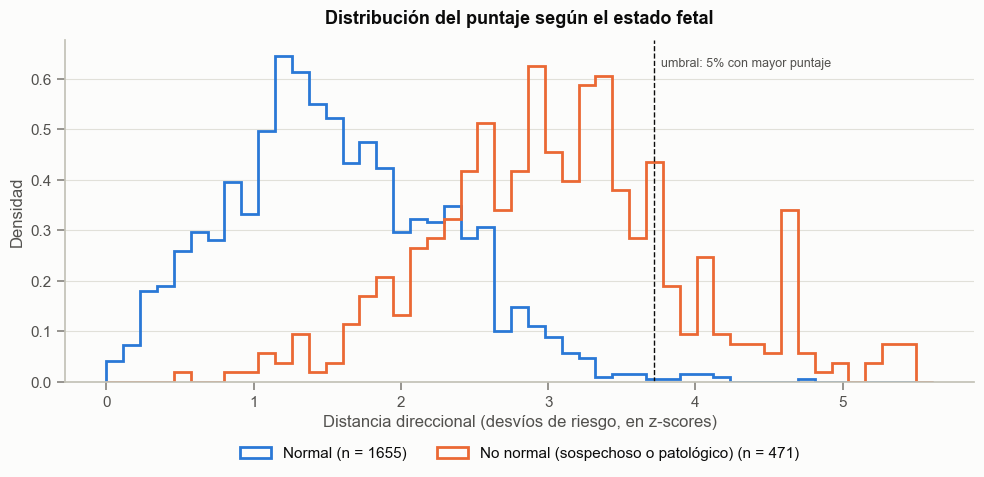

In [8]:
fig = plots.plot_score_distribution(puntaje, y, umbral)
plots.save_figure(fig, "distribucion_puntaje")

Los CTG normales se concentran en puntajes bajos, con un pico cerca de 1,2; los no normales, alrededor de 3, con una cola larga hacia la derecha. Por encima del umbral (3,72) quedan casi sólo CTG no normales, pero la mayoría de ellos tiene puntajes entre 2 y 3,7, donde se superponen con los normales. Por eso el recall al 5% es bajo (20%), aunque la precisión sea alta.

### 6.2 Curva ROC

Se compara con la distancia euclídea común sobre las mismas variables (el mismo método sin la dirección de riesgo) y con el mejor método del notebook de clase (Isolation Forest con `RobustScaler` y las 21 variables).

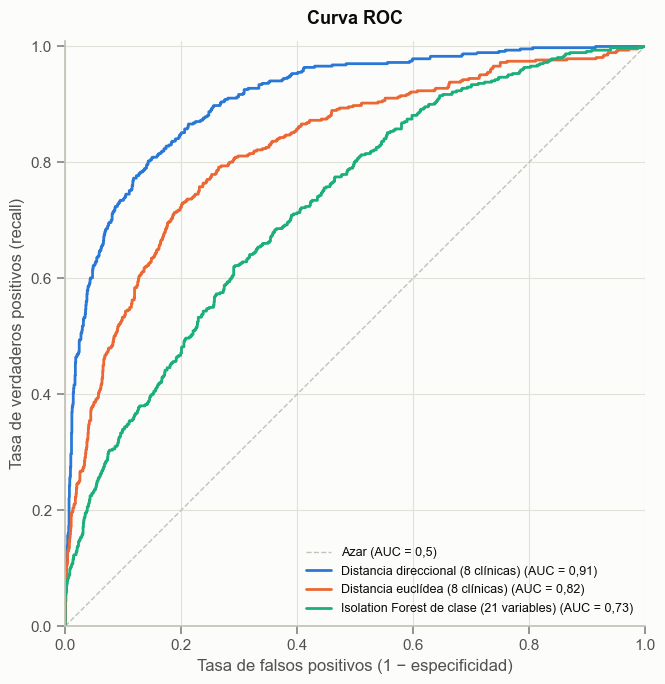

In [9]:
curvas = {
    "Distancia direccional (8 clínicas)": puntaje,
    "Distancia euclídea (8 clínicas)": center_distance(Z),
    "Isolation Forest de clase (21 variables)": isolation_score(robust_scale(X)),
}
fig = plots.plot_roc(curvas, y)
plots.save_figure(fig, "curva_roc")

La curva de la distancia direccional queda por encima de las otras dos en casi todo el rango. La diferencia con la distancia euclídea (0,91 contra 0,82) es lo que aporta contar sólo los desvíos de riesgo, con las mismas variables y el mismo preprocesamiento.

### 6.3 Qué variables aportan al puntaje

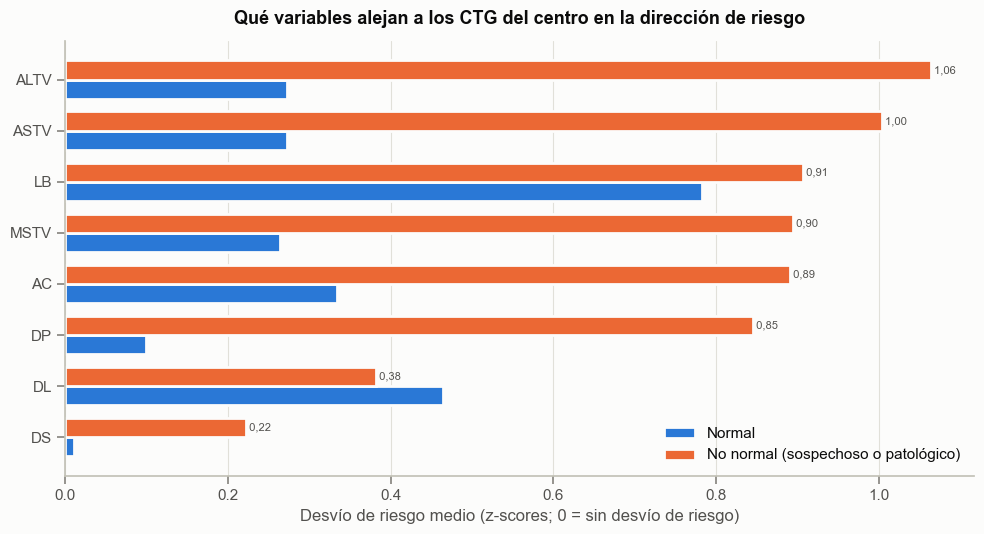

In [10]:
fig = plots.plot_contributions(aportes, y)
plots.save_figure(fig, "aportes_por_variable")

En los CTG no normales, los mayores desvíos de riesgo vienen de la variabilidad (`ALTV`, `ASTV` y `MSTV`), seguidos por la falta de aceleraciones (`AC`) y las desaceleraciones prolongadas (`DP`). En todas ellas, el aporte es entre 2,7 veces (`AC`) y 8,5 veces (`DP`) mayor que en los normales.

Dos variables discriminan poco:

- **`LB`**: como cuenta el desvío en cualquier sentido (|z|), tiene un aporte alto también en los normales (0,78 contra 0,91).
- **`DL`**: su aporte es incluso algo mayor en los normales (0,46 contra 0,38). Las desaceleraciones leves son frecuentes en CTG sanos, así que considerarlas de riesgo suma ruido.

Las desaceleraciones severas (`DS`) tienen un aporte medio bajo porque aparecen en muy pocos CTG, pero cuando aparecen pesan mucho en el puntaje de ese registro.

### 6.4 Elección del umbral

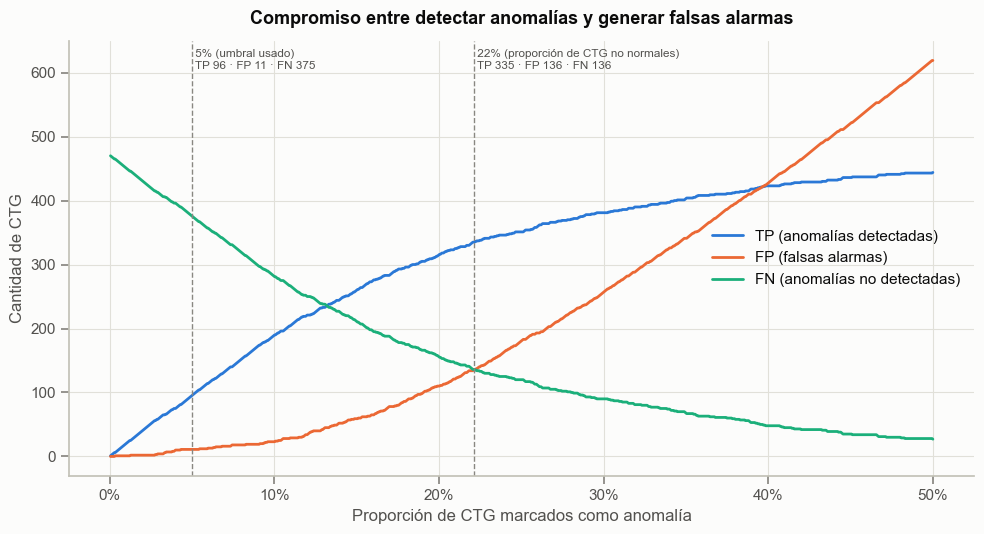

In [11]:
fig = plots.plot_tradeoff(puntaje, y, {
    "5% (umbral usado)": CONTAMINATION,
    f"{y.mean():.0%} (proporción de CTG no normales)": y.mean(),
})
plots.save_figure(fig, "compromiso_umbral")

El umbral define el compromiso entre detectar anomalías y generar falsas alarmas:

- **Al 5%**, el método casi no genera falsas alarmas (11 FP), pero detecta sólo una de cada cinco anomalías (375 FN).
- **Al 22%**, la proporción esperada de CTG no normales, detecta 7 de cada 10 anomalías (335 TP y 136 FN), a cambio de 136 falsas alarmas.

En un contexto clínico, una anomalía no detectada suele ser más costosa que una falsa alarma, lo que justificaría un umbral más alto que el 5%. Pero ese costo es una decisión clínica, no estadística.

## 7. Conclusión

La distancia direccional es simple: una distancia euclídea sobre 8 variables, sin entrenar ningún modelo ni ajustar hiperparámetros. Supera a todos los métodos probados (ROC-AUC de 0,91, contra 0,73 del mejor método de clase) porque incorpora un conocimiento que los métodos genéricos no tienen: en medicina, apartarse de lo típico no es anómalo si es en la dirección sana.

**Limitación:** la dirección de riesgo de cada variable sale del criterio clínico, no de las etiquetas, pero el resultado se evaluó contra la misma etiqueta con la que se compararon los métodos. Para confirmarlo habría que validarlo en otro conjunto de CTG.